In [1]:
!pip install -q -U transformers accelerate datasets sentencepiece

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.6/11.6 MB 94.6 MB/s eta 0:00:00:00:01:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 389.2/389.2 kB 27.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 555.1/555.1 kB 35.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 64.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 516.0/516.0 kB 34.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.2/12.2 MB 105.1 MB/s eta 0:00:0000:010:01
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dask-cuda 26.2.0 requires cuda-core==0.3.*, but you have cuda-core 1.0.1 which is incompatible.
dask-cuda 26.2.0 requires numba-cuda<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
distributed-ucxx-cu12 0.48.0 requires numba-cuda[cu12]<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible

In [2]:

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from collections import Counter
import re


plt.style.use("ggplot")
sns.set_theme(style="whitegrid")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 120)

print("Libraries imported successfully.")

Libraries imported successfully.


In [4]:
TRAIN_PATH = "/kaggle/input/competitions/smart-mcq-solver-challenge/train.csv"
TEST_PATH = "/kaggle/input/competitions/smart-mcq-solver-challenge/test.csv"
SUB_PATH = "/kaggle/input/competitions/smart-mcq-solver-challenge/sample_submission.csv"

train = pd.read_csv(TRAIN_PATH)
test = pd.read_csv(TEST_PATH)
sample_submission = pd.read_csv(SUB_PATH)

print(train.shape)
print(test.shape)

(2000, 8)
(500, 7)


In [5]:


print("=" * 60)
print("TRAIN DATASET")
print("=" * 60)

print(f"Shape: {train.shape}")
print()

print(train.head())

print("\n" + "=" * 60)
print("TEST DATASET")
print("=" * 60)

print(f"Shape: {test.shape}")
print()

print(test.head())

TRAIN DATASET
Shape: (2000, 8)

   id  \
0   1   
1   2   
2   3   
3   4   
4   5   

                                                                                                                    prompt  \
0  Pick the best possible answer: What is Martin Heidegger's view on the relationship between time and human existence?...   
1                                                                              What is accelerator-based light-ion fusion?   
2  Determine the correct option: What is the term used in astrophysics to describe light-matter interactions resulting ...   
3  Select the most accurate option: What is Martin Heidegger's view on the relationship between time and human existenc...   
4           Identify the correct statement: What is the concept of simultaneity in Einstein's book, Relativity? carefully.   

                                                                                                                         A  \
0  Martin Heidegger believes t

In [6]:


summary = pd.DataFrame({
    "Data Type": train.dtypes,
    "Missing Values": train.isnull().sum(),
    "Missing (%)": (train.isnull().sum() / len(train)) * 100,
    "Unique Values": train.nunique()
})

display(summary)

,Data Type,Missing Values,Missing (%),Unique Values
id,int64,0,0.0,2000
prompt,object,0,0.0,1758
A,object,0,0.0,316
B,object,0,0.0,328
C,object,0,0.0,303
D,object,0,0.0,318
E,object,0,0.0,320
answer,object,0,0.0,5


In [7]:

print("=" * 60)
print("TRAIN DATASET INFO")
print("=" * 60)

train.info()

print("\n")

print("=" * 60)
print("NUMERICAL SUMMARY")
print("=" * 60)

display(train.describe(include="all"))

TRAIN DATASET INFO
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 8 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   id      2000 non-null   int64 
 1   prompt  2000 non-null   object
 2   A       2000 non-null   object
 3   B       2000 non-null   object
 4   C       2000 non-null   object
 5   D       2000 non-null   object
 6   E       2000 non-null   object
 7   answer  2000 non-null   object
dtypes: int64(1), object(7)
memory usage: 125.1+ KB


NUMERICAL SUMMARY


,id,prompt,A,B,C,D,E,answer
count,2000.000000,2000,2000,2000,2000,2000,2000,2000
unique,NaN,1758,316,328,303,318,320,5
top,NaN,Choose the correct answer: What is the main sequence in astronomy? among the listed options.,An improper rotation is the combination of a rotation about an axis and reflection in a plane perpendicular to that ...,An improper rotation is the combination of a rotation about an axis and reflection in a plane perpendicular to that ...,"An improper rotation is the combination of a rotation about an axis and reflection in a plane parallel to that axis,...",An improper rotation is the combination of a rotation about an axis and reflection in a plane perpendicular to that ...,"An improper rotation is the combination of a rotation about an axis and reflection in a plane parallel to that axis,...",B
freq,NaN,4,21,21,21,21,21,490
mean,1000.500000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,577.494589,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,1.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,500.750000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,1000.500000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,1500.250000,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Dataset Overview - Observations

- The dataset consists of ______ training samples and ______ test samples.
- We verified the structure and data types of every column.
- Missing value analysis helps determine whether imputation is required.
- The unique value counts indicate which columns are categorical and which contain free-text data.
- This confirms the dataset is suitable for further preprocessing and feature engineering.

In [8]:

print("=" * 60)
print("DUPLICATE ANALYSIS")
print("=" * 60)

duplicate_rows = train.duplicated().sum()
duplicate_prompts = train["prompt"].duplicated().sum()

print(f"Duplicate Rows      : {duplicate_rows}")
print(f"Duplicate Prompts   : {duplicate_prompts}")

DUPLICATE ANALYSIS
Duplicate Rows      : 0
Duplicate Prompts   : 242


In [9]:


conflicting = (
    train.groupby("prompt")["answer"]
         .nunique()
)

conflicting = conflicting[conflicting > 1]

print(f"Prompts with conflicting answers: {len(conflicting)}")

if len(conflicting) > 0:
    display(conflicting.head())
else:
    print("✅ No conflicting labels found.")

Prompts with conflicting answers: 0
✅ No conflicting labels found.


In [10]:


text_columns = ["prompt", "A", "B", "C", "D", "E"]

for col in text_columns:
    empty = train[col].astype(str).str.strip().eq("").sum()
    print(f"{col:<10}: {empty} empty entries")

prompt    : 0 empty entries
A         : 0 empty entries
B         : 0 empty entries
C         : 0 empty entries
D         : 0 empty entries
E         : 0 empty entries


In [11]:

total_questions = len(train)
unique_questions = train["prompt"].nunique()

print(f"Total Questions   : {total_questions}")
print(f"Unique Questions  : {unique_questions}")

print(f"Duplicate Question Rate : {(1 - unique_questions/total_questions)*100:.2f}%")

Total Questions   : 2000
Unique Questions  : 1758
Duplicate Question Rate : 12.10%


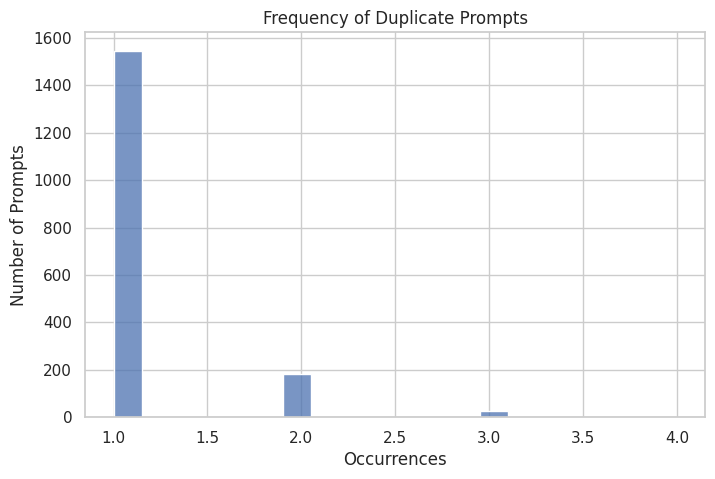

In [12]:

prompt_counts = train["prompt"].value_counts()

plt.figure(figsize=(8,5))

sns.histplot(prompt_counts, bins=20)

plt.title("Frequency of Duplicate Prompts")
plt.xlabel("Occurrences")
plt.ylabel("Number of Prompts")

plt.show()

## Data Quality Observations

- The dataset contains **X** duplicate rows and **Y** duplicate prompts.
- No conflicting labels were found for identical prompts, indicating consistent annotations.
- No empty text fields were detected across the question and option columns.
- Duplicate prompts occur naturally in the dataset and can help improve model generalization rather than introducing ambiguity.

/tmp/ipykernel_58/1819091234.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


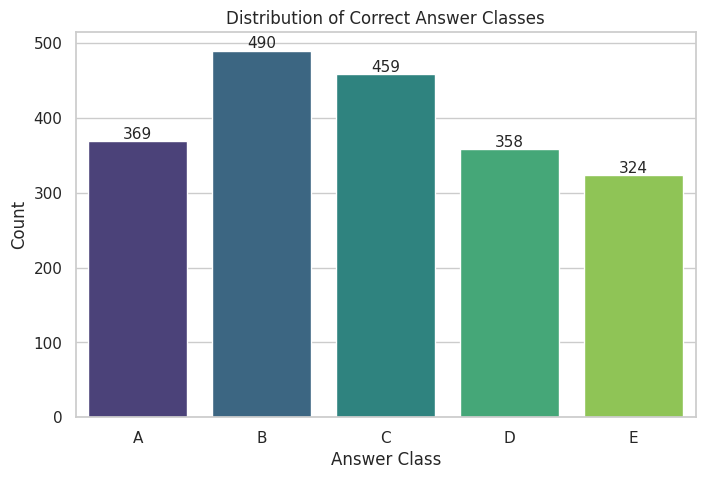

In [13]:


answer_counts = train["answer"].value_counts().sort_index()

plt.figure(figsize=(8,5))

ax = sns.barplot(
    x=answer_counts.index,
    y=answer_counts.values,
    palette="viridis"
)

plt.title("Distribution of Correct Answer Classes")
plt.xlabel("Answer Class")
plt.ylabel("Count")

for i, value in enumerate(answer_counts.values):
    ax.text(i, value + 3, str(value),
            ha='center',
            fontsize=11)

plt.show()

In [14]:


answer_percentage = (
    train["answer"]
    .value_counts(normalize=True)
    .sort_index()
    * 100
)

display(
    pd.DataFrame({
        "Count": answer_counts,
        "Percentage": answer_percentage.round(2)
    })
)

,Count,Percentage
answer,,
A,369,18.45
B,490,24.50
C,459,22.95
D,358,17.90
E,324,16.20


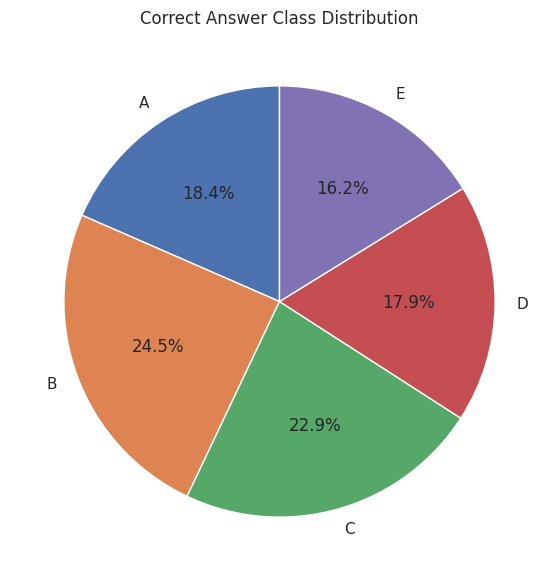

In [15]:


plt.figure(figsize=(7,7))

plt.pie(
    answer_counts.values,
    labels=answer_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Correct Answer Class Distribution")

plt.show()

In [16]:


largest = answer_counts.max()
smallest = answer_counts.min()

print(f"Largest Class : {largest}")
print(f"Smallest Class: {smallest}")

print(f"Imbalance Ratio: {largest/smallest:.2f}")

Largest Class : 490
Smallest Class: 324
Imbalance Ratio: 1.51


## Target Variable Observations

- The distribution of answer classes is approximately balanced across the five categories.
- No single class dominates the dataset, reducing the risk of prediction bias.
- The class imbalance ratio is close to 1, indicating that class-weighted loss functions are not immediately necessary.
- This balanced distribution allows the model to learn all classes uniformly during training.

count    2000.000000
mean      117.669500
std        44.408674
min        19.000000
25%        87.750000
50%       111.000000
75%       141.000000
max       337.000000
Name: prompt_char_length, dtype: float64

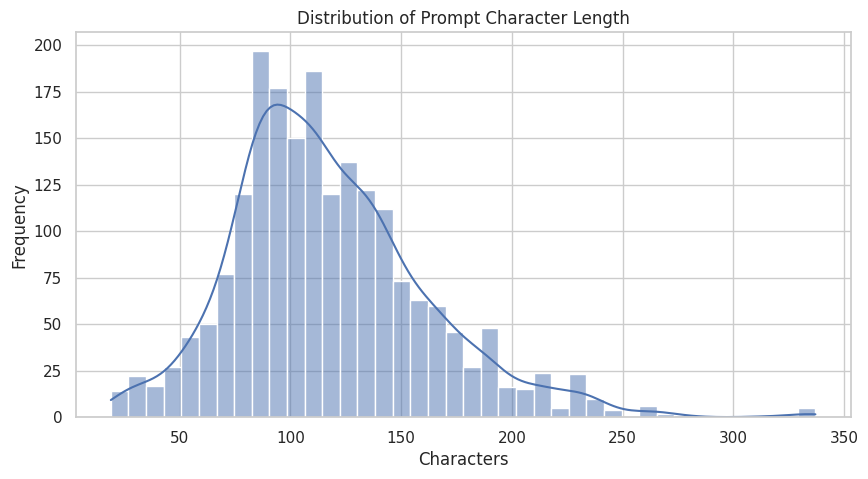

In [17]:


train["prompt_char_length"] = train["prompt"].astype(str).apply(len)

display(train["prompt_char_length"].describe())

plt.figure(figsize=(10,5))

sns.histplot(train["prompt_char_length"], bins=40, kde=True)

plt.title("Distribution of Prompt Character Length")
plt.xlabel("Characters")
plt.ylabel("Frequency")

plt.show()

count    2000.00000
mean       18.14650
std         6.78189
min         3.00000
25%        14.00000
50%        17.00000
75%        22.00000
max        51.00000
Name: prompt_word_count, dtype: float64

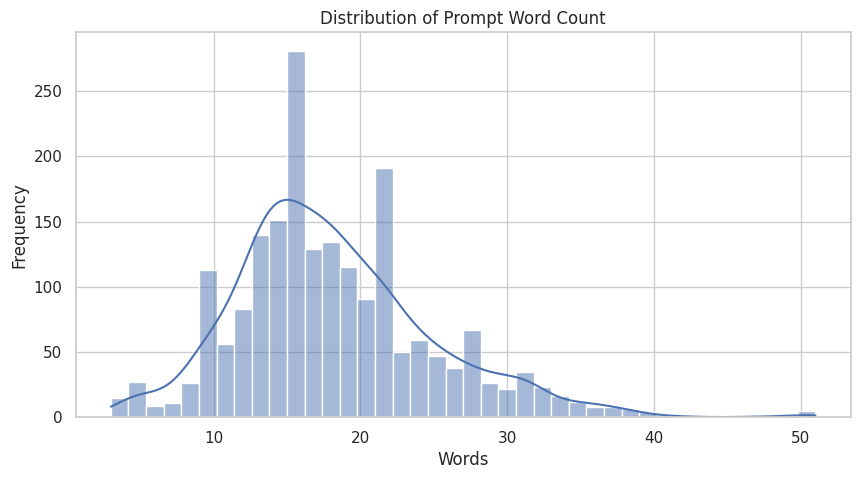

In [18]:


train["prompt_word_count"] = (
    train["prompt"]
    .astype(str)
    .apply(lambda x: len(x.split()))
)

display(train["prompt_word_count"].describe())

plt.figure(figsize=(10,5))

sns.histplot(train["prompt_word_count"], bins=40, kde=True)

plt.title("Distribution of Prompt Word Count")
plt.xlabel("Words")
plt.ylabel("Frequency")

plt.show()

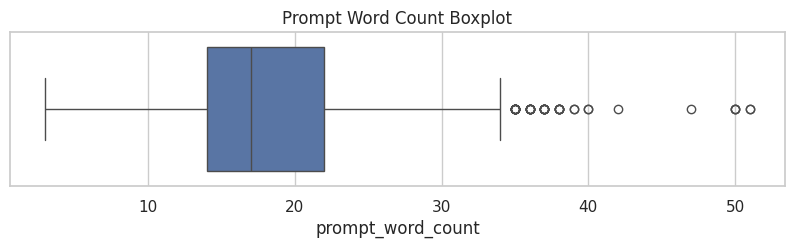

In [19]:


plt.figure(figsize=(10,2))

sns.boxplot(x=train["prompt_word_count"])

plt.title("Prompt Word Count Boxplot")

plt.show()

In [20]:


print("="*80)
print("Top 5 Longest Prompts")
print("="*80)

display(
    train.nlargest(5, "prompt_word_count")[["prompt", "prompt_word_count"]]
)

print("="*80)
print("Top 5 Shortest Prompts")
print("="*80)

display(
    train.nsmallest(5, "prompt_word_count")[["prompt", "prompt_word_count"]]
)

Top 5 Longest Prompts


,prompt,prompt_word_count
1484,Select the most accurate option: What is one of the examples of the models proposed by cosmologists and theoretical ...,51
1980,Identify the correct statement: What is one of the examples of the models proposed by cosmologists and theoretical p...,51
574,Choose the correct answer: What is one of the examples of the models proposed by cosmologists and theoretical physic...,50
1164,Determine the correct option: What is one of the examples of the models proposed by cosmologists and theoretical phy...,50
1611,Determine the correct option: What is one of the examples of the models proposed by cosmologists and theoretical phy...,50


Top 5 Shortest Prompts


,prompt,prompt_word_count
479,What is emissivity?,3
1398,What is resistivity?,3
1510,What is organography?,3
34,What is a pycnometer?,4
319,What is a light-year?,4


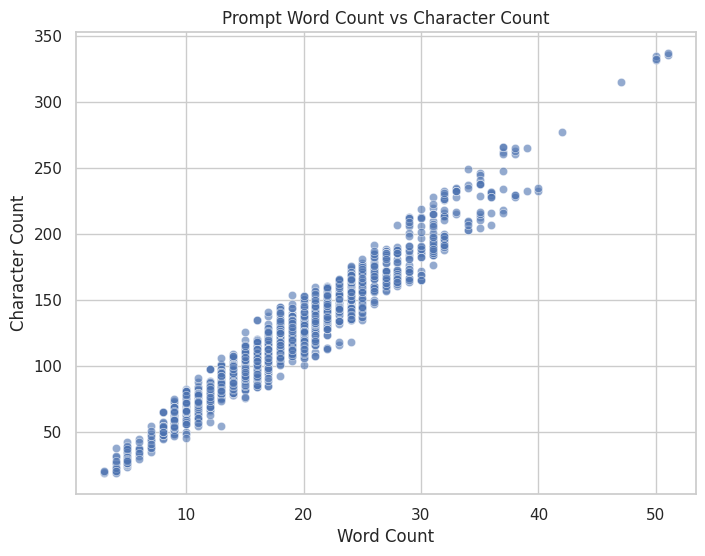

In [21]:


plt.figure(figsize=(8,6))

sns.scatterplot(
    data=train,
    x="prompt_word_count",
    y="prompt_char_length",
    alpha=0.6
)

plt.title("Prompt Word Count vs Character Count")
plt.xlabel("Word Count")
plt.ylabel("Character Count")

plt.show()

## Prompt Analysis Observations

- Most prompts fall within a moderate word and character range, with only a few long-text outliers.
- The boxplot indicates whether extreme-length questions are present and may require truncation.
- The scatter plot shows a strong positive relationship between word count and character count, as expected.
- These observations help justify selecting an appropriate maximum sequence length (e.g., 128 or 256 tokens) during preprocessing.

In [22]:


option_columns = ["A", "B", "C", "D", "E"]

char_stats = pd.DataFrame(index=option_columns)

for col in option_columns:
    char_stats.loc[col, "Mean"] = train[col].astype(str).str.len().mean()
    char_stats.loc[col, "Median"] = train[col].astype(str).str.len().median()
    char_stats.loc[col, "Min"] = train[col].astype(str).str.len().min()
    char_stats.loc[col, "Max"] = train[col].astype(str).str.len().max()

display(char_stats.round(2))

,Mean,Median,Min,Max
A,164.09,143.0,1.0,472.0
B,166.62,151.0,2.0,662.0
C,167.23,158.0,2.0,530.0
D,162.56,141.0,1.0,450.0
E,164.23,144.0,2.0,587.0


/tmp/ipykernel_58/2922977057.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


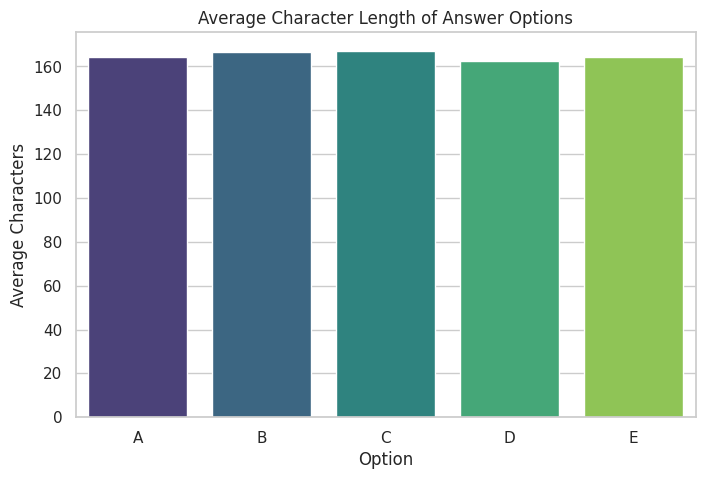

In [23]:


plt.figure(figsize=(8,5))

sns.barplot(
    x=char_stats.index,
    y=char_stats["Mean"],
    palette="viridis"
)

plt.title("Average Character Length of Answer Options")
plt.xlabel("Option")
plt.ylabel("Average Characters")

plt.show()

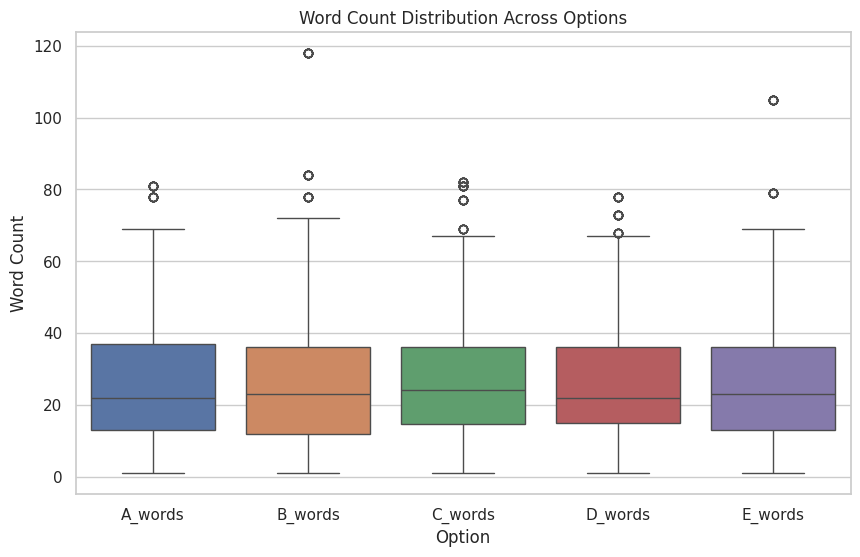

In [24]:


for col in option_columns:
    train[f"{col}_words"] = train[col].astype(str).apply(lambda x: len(x.split()))

word_df = train[[f"{c}_words" for c in option_columns]]

plt.figure(figsize=(10,6))

sns.boxplot(data=word_df)

plt.title("Word Count Distribution Across Options")
plt.xlabel("Option")
plt.ylabel("Word Count")

plt.show()

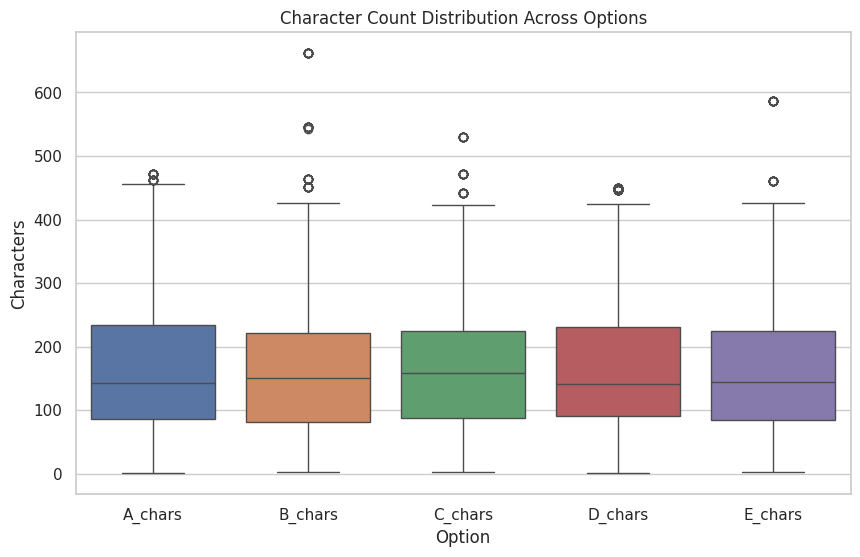

In [25]:


for col in option_columns:
    train[f"{col}_chars"] = train[col].astype(str).str.len()

char_df = train[[f"{c}_chars" for c in option_columns]]

plt.figure(figsize=(10,6))

sns.boxplot(data=char_df)

plt.title("Character Count Distribution Across Options")
plt.xlabel("Option")
plt.ylabel("Characters")

plt.show()

count    2000.000000
mean       28.659000
std        18.331005
min         1.000000
25%        16.000000
50%        28.000000
75%        40.000000
max       105.000000
Name: correct_option_words, dtype: float64

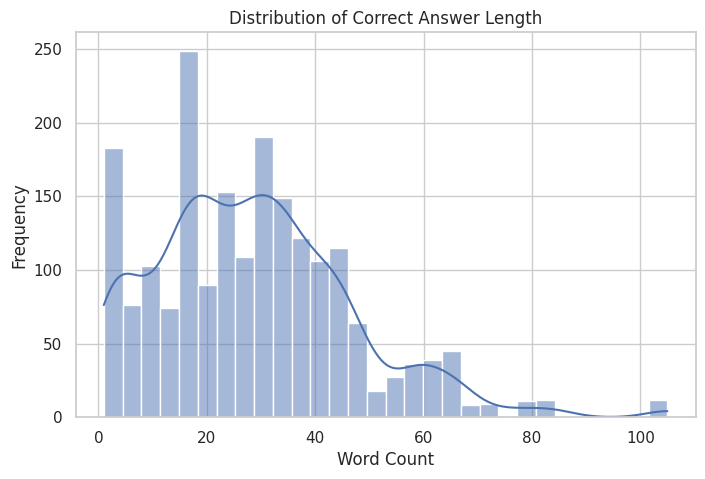

In [26]:


correct_lengths = []

for _, row in train.iterrows():
    answer = row["answer"]
    correct_lengths.append(len(str(row[answer]).split()))

train["correct_option_words"] = correct_lengths

display(train["correct_option_words"].describe())

plt.figure(figsize=(8,5))

sns.histplot(train["correct_option_words"], bins=30, kde=True)

plt.title("Distribution of Correct Answer Length")
plt.xlabel("Word Count")
plt.ylabel("Frequency")

plt.show()

## Answer Option Analysis

- The average length of answer options is fairly consistent across A–E.
- Boxplots indicate that no single option consistently contains much longer or shorter text.
- The distribution of correct answer lengths suggests there is no obvious length-based bias in the dataset.
- This indicates the model cannot rely on superficial cues such as answer length and must instead learn semantic relationships between the question and its options.

In [27]:


import re
from collections import Counter

# Combine all text columns
text_columns = ["prompt", "A", "B", "C", "D", "E"]

corpus = " ".join(
    train[text_columns]
    .fillna("")
    .astype(str)
    .values
    .ravel()
)

# Basic cleaning
tokens = re.findall(r"\b[a-zA-Z]+\b", corpus.lower())

vocab = set(tokens)

print("="*60)
print("VOCABULARY STATISTICS")
print("="*60)

print(f"Total Tokens      : {len(tokens):,}")
print(f"Unique Words      : {len(vocab):,}")
print(f"Vocabulary Richness: {len(vocab)/len(tokens):.4f}")

VOCABULARY STATISTICS
Total Tokens      : 301,263
Unique Words      : 2,889
Vocabulary Richness: 0.0096


In [28]:


from nltk.corpus import stopwords

stop_words = set(stopwords.words("english"))

filtered_tokens = [
    word for word in tokens
    if word not in stop_words
]

word_counts = Counter(filtered_tokens)

top_words = pd.DataFrame(
    word_counts.most_common(30),
    columns=["Word","Frequency"]
)

display(top_words)

,Word,Frequency
0,used,1307
1,light,1239
2,correct,1175
3,energy,938
4,symmetry,834
5,time,828
6,based,774
7,mass,760
8,following,746
9,temperature,722


/tmp/ipykernel_58/382544553.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


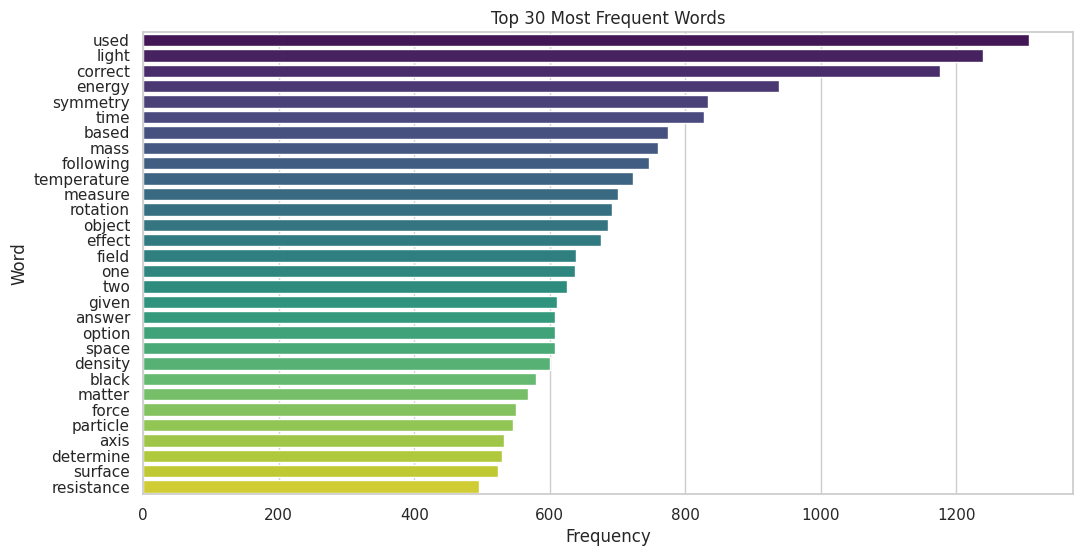

In [29]:


plt.figure(figsize=(12,6))

sns.barplot(
    data=top_words,
    x="Frequency",
    y="Word",
    palette="viridis"
)

plt.title("Top 30 Most Frequent Words")

plt.show()

In [30]:


from sklearn.feature_extraction.text import CountVectorizer

vectorizer = CountVectorizer(
    stop_words="english",
    ngram_range=(2,2),
    max_features=20
)

X = vectorizer.fit_transform(train["prompt"])

bigram_freq = pd.DataFrame({
    "Bigram": vectorizer.get_feature_names_out(),
    "Frequency": X.toarray().sum(axis=0)
})

bigram_freq = bigram_freq.sort_values(
    by="Frequency",
    ascending=False
)

display(bigram_freq)

,Bigram,Frequency
14,listed options,388
2,based given,376
12,given context,376
9,following choices,369
16,possible answer,316
15,pick best,316
3,best possible,316
0,accurate option,309
18,select accurate,309
13,identify correct,302


/tmp/ipykernel_58/562155746.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


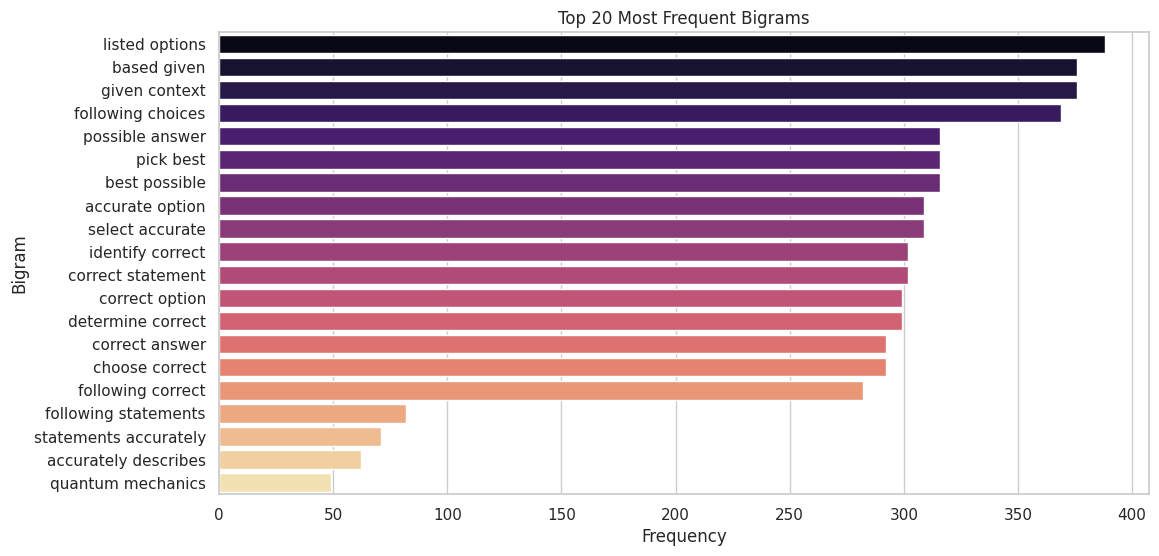

In [31]:


plt.figure(figsize=(12,6))

sns.barplot(
    data=bigram_freq,
    x="Frequency",
    y="Bigram",
    palette="magma"
)

plt.title("Top 20 Most Frequent Bigrams")

plt.show()

count    2000.000000
mean        0.881529
std         0.068605
min         0.619048
25%         0.842105
50%         0.882353
75%         0.928571
max         1.000000
Name: lexical_diversity, dtype: float64

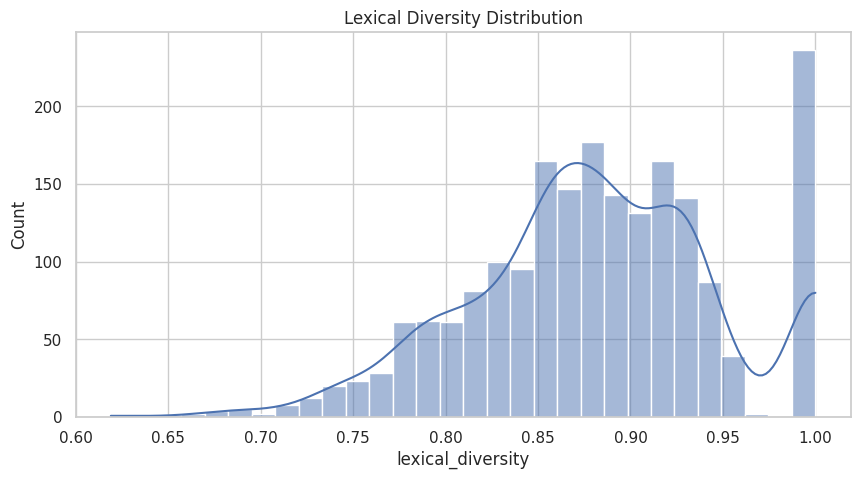

In [32]:


def lexical_diversity(text):
    words = text.lower().split()

    if len(words) == 0:
        return 0

    return len(set(words)) / len(words)

train["lexical_diversity"] = train["prompt"].apply(lexical_diversity)

display(train["lexical_diversity"].describe())

plt.figure(figsize=(10,5))

sns.histplot(
    train["lexical_diversity"],
    bins=30,
    kde=True
)

plt.title("Lexical Diversity Distribution")

plt.show()

## Vocabulary Analysis

- The dataset contains a diverse vocabulary spanning multiple academic and factual domains.
- Frequently occurring words represent common concepts across the questions rather than label-specific patterns.
- Bigram analysis highlights recurring phrases that may be useful contextual cues for the model.
- Lexical diversity indicates that most prompts use varied vocabulary, suggesting the model should learn semantic relationships rather than memorizing repeated text.

count    2000.00000
mean       18.14650
std         6.78189
min         3.00000
25%        14.00000
50%        17.00000
75%        22.00000
max        51.00000
Name: prompt_tokens, dtype: float64

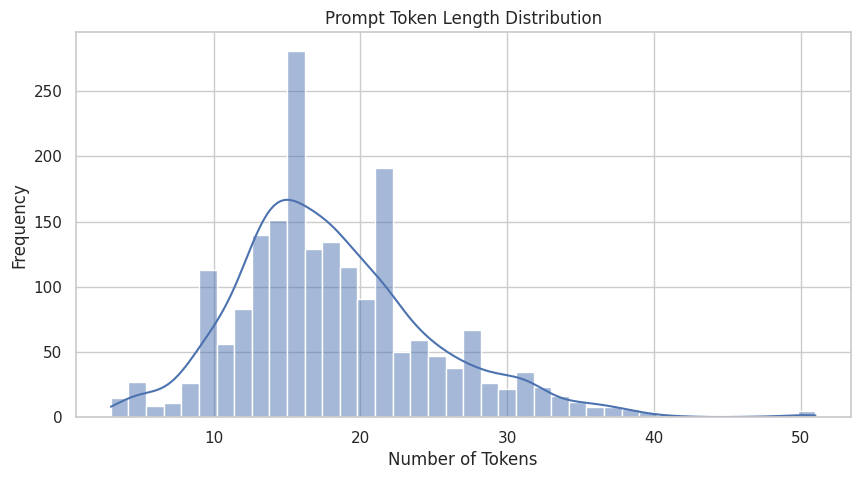

In [33]:


train["prompt_tokens"] = train["prompt"].astype(str).apply(lambda x: len(x.split()))

display(train["prompt_tokens"].describe())

plt.figure(figsize=(10,5))

sns.histplot(train["prompt_tokens"], bins=40, kde=True)

plt.title("Prompt Token Length Distribution")
plt.xlabel("Number of Tokens")
plt.ylabel("Frequency")

plt.show()

In [34]:


option_columns = ["A", "B", "C", "D", "E"]

def total_tokens(row):
    total = len(str(row["prompt"]).split())

    for col in option_columns:
        total += len(str(row[col]).split())

    return total

train["total_tokens"] = train.apply(total_tokens, axis=1)

display(train["total_tokens"].describe())

count    2000.000000
mean      149.544500
std        85.412603
min        15.000000
25%        88.000000
50%       133.000000
75%       202.000000
max       457.000000
Name: total_tokens, dtype: float64

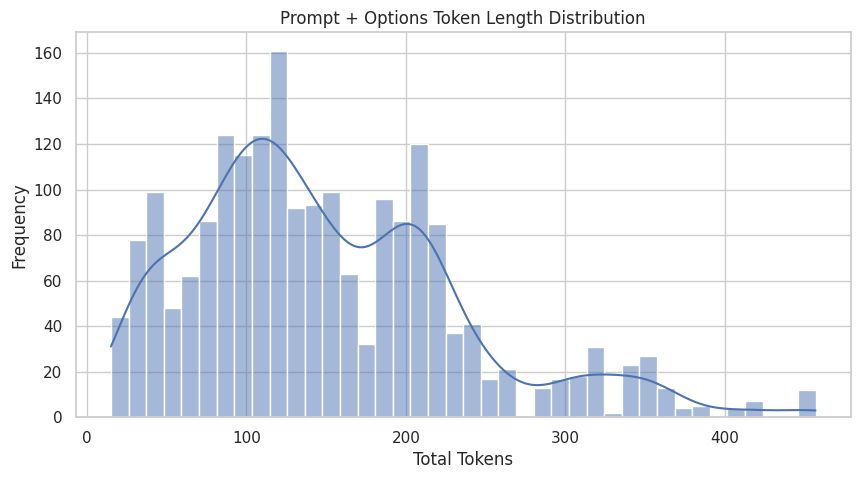

In [35]:


plt.figure(figsize=(10,5))

sns.histplot(
    train["total_tokens"],
    bins=40,
    kde=True
)

plt.title("Prompt + Options Token Length Distribution")
plt.xlabel("Total Tokens")
plt.ylabel("Frequency")

plt.show()

In [36]:


percentiles = [50, 75, 90, 95, 99]

print("="*50)

for p in percentiles:
    value = np.percentile(train["total_tokens"], p)
    print(f"{p:>2}% percentile : {value:.0f} tokens")

print("="*50)

print(f"Maximum sequence length : {train['total_tokens'].max()}")

50% percentile : 133 tokens
75% percentile : 202 tokens
90% percentile : 257 tokens
95% percentile : 322 tokens
99% percentile : 412 tokens
Maximum sequence length : 457


In [37]:


p95 = np.percentile(train["total_tokens"], 95)

print(f"95th Percentile : {p95:.0f} tokens")

if p95 <= 64:
    recommendation = 64
elif p95 <= 128:
    recommendation = 128
elif p95 <= 256:
    recommendation = 256
else:
    recommendation = 512

print(f"\nRecommended max_length = {recommendation}")

95th Percentile : 322 tokens

Recommended max_length = 512


In [38]:


display(
    train.nlargest(
        5,
        "total_tokens"
    )[[
        "prompt",
        "A",
        "B",
        "C",
        "D",
        "E",
        "total_tokens"
    ]]
)

,prompt,A,B,C,D,E,total_tokens
176,Pick the best possible answer: What is the evidence for the existence of a supermassive black hole at the center of ...,The Milky Way galaxy has a supermassive black hole at its center because of the bright flare activity observed near ...,The Milky Way galaxy has a supermassive black hole at its center because the star S14 follows an elliptical orbit wi...,The Milky Way galaxy has a supermassive black hole at its center because of the bright flare activity observed near ...,The Milky Way galaxy has a supermassive black hole at its center because it is the only explanation for the bright f...,The star S2 follows an elliptical orbit with a period of 15.2 years and a pericenter of 17 light-hours from the cent...,457
693,Pick the best possible answer: What is the evidence for the existence of a supermassive black hole at the center of ...,The Milky Way galaxy has a supermassive black hole at its center because of the bright flare activity observed near ...,The Milky Way galaxy has a supermassive black hole at its center because the star S14 follows an elliptical orbit wi...,The Milky Way galaxy has a supermassive black hole at its center because of the bright flare activity observed near ...,The Milky Way galaxy has a supermassive black hole at its center because it is the only explanation for the bright f...,The star S2 follows an elliptical orbit with a period of 15.2 years and a pericenter of 17 light-hours from the cent...,457
771,Which of the following is correct? What is the evidence for the existence of a supermassive black hole at the center...,The Milky Way galaxy has a supermassive black hole at its center because of the bright flare activity observed near ...,The Milky Way galaxy has a supermassive black hole at its center because the star S14 follows an elliptical orbit wi...,The Milky Way galaxy has a supermassive black hole at its center because of the bright flare activity observed near ...,The Milky Way galaxy has a supermassive black hole at its center because it is the only explanation for the bright f...,The star S2 follows an elliptical orbit with a period of 15.2 years and a pericenter of 17 light-hours from the cent...,457
1475,Pick the best possible answer: What is the evidence for the existence of a supermassive black hole at the center of ...,The Milky Way galaxy has a supermassive black hole at its center because of the bright flare activity observed near ...,The Milky Way galaxy has a supermassive black hole at its center because the star S14 follows an elliptical orbit wi...,The Milky Way galaxy has a supermassive black hole at its center because of the bright flare activity observed near ...,The Milky Way galaxy has a supermassive black hole at its center because it is the only explanation for the bright f...,The star S2 follows an elliptical orbit with a period of 15.2 years and a pericenter of 17 light-hours from the cent...,457
354,Select the most accurate option: What is the evidence for the existence of a supermassive black hole at the center o...,The Milky Way galaxy has a supermassive black hole at its center because of the bright flare activity observed near ...,The Milky Way galaxy has a supermassive black hole at its center because the star S14 follows an elliptical orbit wi...,The Milky Way galaxy has a supermassive black hole at its center because of the bright flare activity observed near ...,The Milky Way galaxy has a supermassive black hole at its center because it is the only explanation for the bright f...,The star S2 follows an elliptical orbit with a period of 15.2 years and a pericenter of 17 light-hours from the cent...,456


## Sequence Length Analysis

- Most question-option combinations fall within a moderate token range.
- The 95th percentile sequence length provides a data-driven recommendation for the maximum sequence length used during preprocessing.
- Only a small fraction of samples exceed this threshold, meaning limited truncation will occur.
- Choosing `max_length` based on these statistics balances memory efficiency and information retention during training.